## Particle Filter Design and Implementation

#### Assumptions
- State 
    - Starting with 1-D localization
- Measurements
    - Captured section of airport runway 
    - Clipped directly from the satellite image
    - Come from same image (eventually from ground image)
- Motion 
    - start with forward propagating motion from a random initial state
    - Constant velocity motion (eventually from INS)
    - UAV stays on centerline, heading aligns with runway
- Weighting
    - 2D comparison between images 
    - Utilizing one of a few methods explored in the lsa_detection script
        - structure tensor, hist, orb
    - TODO: determine score or likelihood function

- Map assumptions 
    - Known image map endpoints for runway (in pixels)
    - Known strip width (in pixels)
    - Size of capture window
    - Ground sample distance (GSD) TODO (m/px)


#### State and Units
State: $s$  (pixels along the strip)


## Checklist
- [x] Setup sim - strip, window size $L$
    - [x] True path (initial $s$, velocity, drift)
    - [ ] Noisy capture 
- [x] Initialization 
    - [x] Uniform over whole runway
    - [x] Initial uav position 
- [x] Prediction: motion plus process noise (eventually INS)
- [ ] Measurement update: 
    - [ ] Compare each particle's window to the capture 
    - [ ] Convert to a likelihood
- [ ] Resampling
- [ ] State Estimate: ??Weighted mean or highest weight mode??
- [ ] Eval:
    - [ ] Error over time 
    - [ ] $N_\text{eff}$: effective sample size: how many particles are really contributing, given spread of weight
    - [ ] Convergence time
    - [ ] Eval over repeated markings

In [1]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt

from pf_sim_1d import *
from map_utils import rectify_strip

# Autosave WORK
%load_ext autoreload
%autoreload 2
%autosave 180

Autosaving every 180 seconds


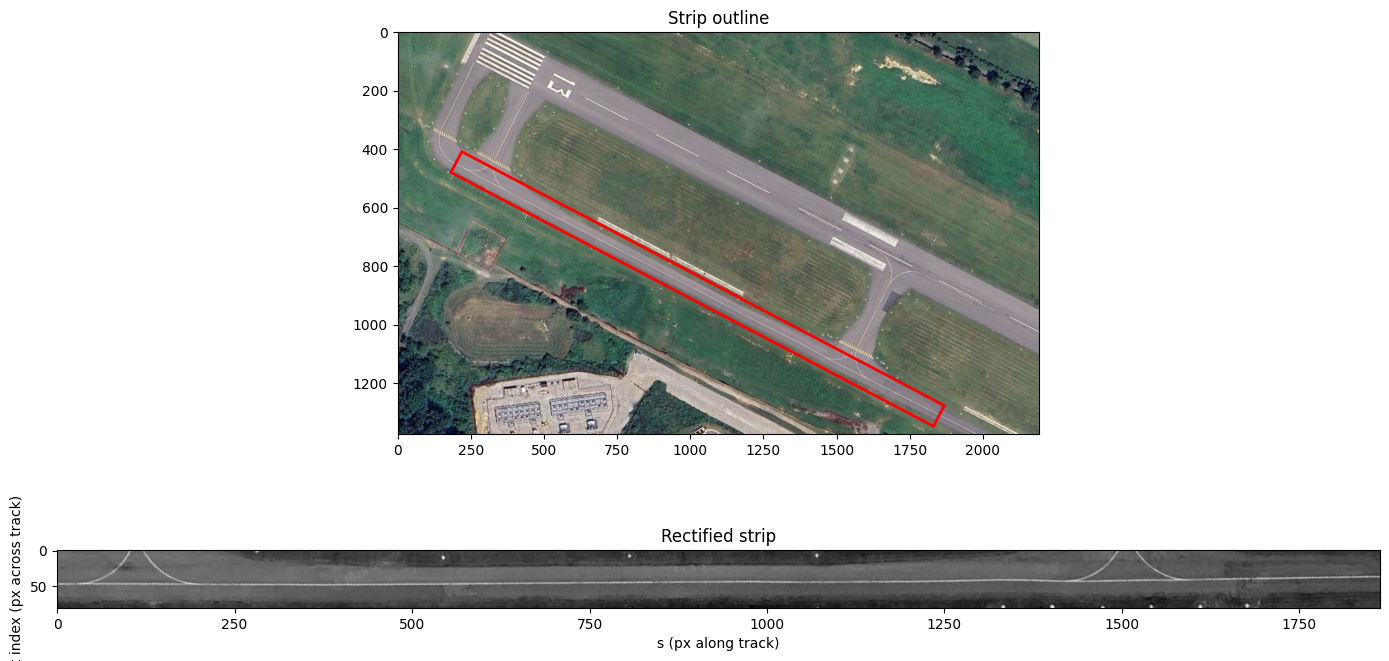

In [2]:
# Satellite imagery 
# sat_ref = "../../datasets/KBCB_satellite/KBCB_partial.jpg" # Public google earth satellite imagery
sat_ref = "../../datasets/KBCB_satellite/KBCB_partial_LSA.png" # Public google earth satellite imagery
sat_rgb = cv2.cvtColor(cv2.imread(sat_ref), cv2.COLOR_BGR2RGB) # Convert color and read
sat_gray = cv2.cvtColor(cv2.imread(sat_ref), cv2.COLOR_BGR2GRAY)

# Known Satellite lane enpoints 
p0, p1 = (200, 444), (1850, 1312)
# known runway halfwdith 
half_w = 40

# Get runway strip and pointer vectors
strip, u, n = rectify_strip(sat_gray, p0, p1, half_w)

# View im
corners = np.array([p0 + half_w*n, p1 + half_w*n, p1 - half_w*n, p0 - half_w*n])
fig, axs = plt.subplots(2, 1, figsize=(14, 8))
axs[0].imshow(sat_rgb)
axs[0].add_patch(plt.Polygon(corners, fill=False, ec='r', lw=2))
axs[0].set_title("Strip outline")
axs[1].imshow(strip, cmap='gray')#, aspect='auto')
axs[1].set_title("Rectified strip")
axs[1].set_xlabel("s (px along track)")
axs[1].set_ylabel("t index (px across track)")
plt.tight_layout()


In [3]:
# Particle filter Initialization 

# Params
L = 100 # Window length 20 pix
n_particles = 100 # Number of particles
sigma_s = 2 # pixel std
random_seed = 17


pf = ParticleFilter1D(strip, L, n_particles, sigma_s, random_seed)

In [4]:
# Generate true trajectory 
rng_start = np.random.default_rng(random_seed)
W = strip.shape[1]
s0 = int(rng_start.integers(W // 3, 2 * W // 3)) # Random but in middle third of strip
v = 10 # Velocity (px/s)
dt = 1 # time step (s)
K = 10 # Steps 

print(f'Initial position (px): {s0} \nVelocity: {v} px/s \nTime step: {dt} s \n{K} steps')


s_true = true_path(s0, v, dt, K)

Initial position (px): 1081 
Velocity: 10 px/s 
Time step: 1 s 
10 steps


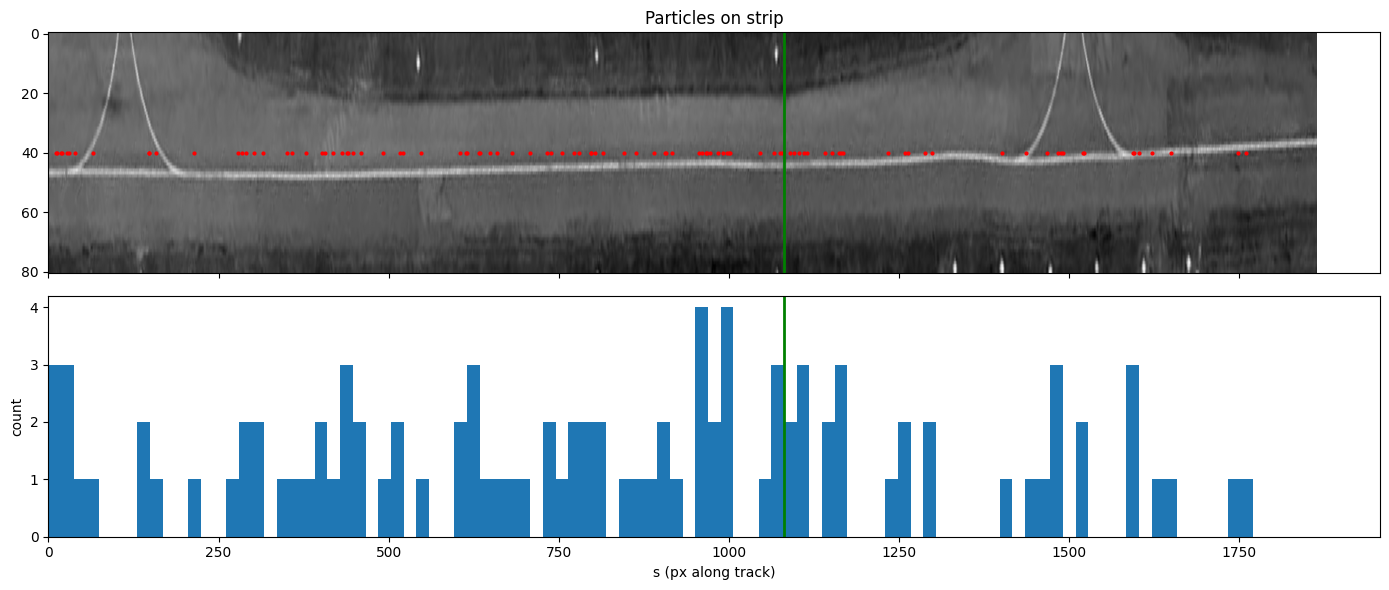

In [5]:
# Initialize particles and view

pf.init_uniform()
plot_curr_particles(strip, pf.particles, s_true[0])

In [6]:
# Predict step 